# Análisis del entrenamiento del carrito DQN

Ejecuta primero `train.py`. Este notebook no entrena: analiza el archivo `results/training_log.csv` y obliga a separar evidencia de interpretación.

## Preguntas previas

1. ¿Qué esperarías que ocurriera con epsilon?
2. ¿Una recompensa creciente garantiza cero colisiones?
3. ¿Por qué conviene usar una media móvil?

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

LOG_PATH = Path('results/training_log.csv')
if not LOG_PATH.exists():
    raise FileNotFoundError('Ejecuta primero: python train.py --episodes 600')
logs = pd.read_csv(LOG_PATH)
display(logs.head())
print(logs.shape)


,episode,reward,steps,success,collision,laps,epsilon,loss_mean,speed_final,action_0,action_1,action_2,action_3,action_4,action_5,action_6,action_7,action_8
0,1,-6.459156,1033,0,1,0.085192,0.978441,0.006951,9.133333,101,111,110,115,103,136,112,114,131
1,2,45.525833,1800,0,0,0.259282,0.942036,0.012806,5.500000,182,233,208,181,183,204,229,180,200
2,3,-3.940965,614,0,1,0.132703,0.929947,0.009586,47.933333,64,111,62,47,83,58,70,66,53
3,4,1.470421,903,0,1,0.154189,0.912466,0.013911,61.666667,98,124,101,97,78,87,136,101,81
4,5,14.514817,808,0,1,0.269125,0.897118,0.015623,83.233333,72,133,93,74,70,96,122,73,75


(145, 18)


In [7]:
logs[['episode', 'reward', 'steps', 'success', 'collision', 'epsilon', 'loss_mean']].describe()


,episode,reward,steps,success,collision,epsilon,loss_mean
count,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000
mean,73.000000,48.425621,314.151724,0.193103,0.793103,0.587557,0.131121
std,42.001984,60.743992,272.172901,0.396102,0.406485,0.123923,0.063303
min,1.000000,-15.688745,89.000000,0.000000,0.000000,0.395225,0.006951
25%,37.000000,1.550869,164.000000,0.000000,1.000000,0.504024,0.075777
50%,73.000000,27.077476,243.000000,0.000000,1.000000,0.571603,0.154873
75%,109.000000,74.237015,368.000000,0.000000,1.000000,0.650026,0.183000
max,145.000000,164.829094,1800.000000,1.000000,1.000000,0.978441,0.226262


## Curvas de aprendizaje

La línea tenue muestra cada episodio; la línea gruesa resume 30 episodios. El suavizado ayuda a ver la tendencia, pero no debe ocultar la variabilidad.

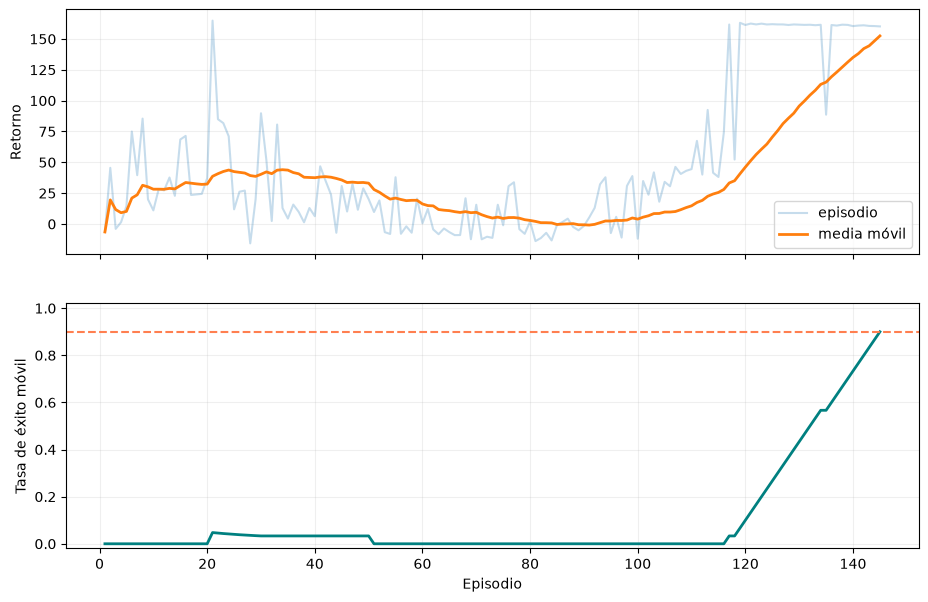

In [4]:
window = 30
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(logs.episode, logs.reward, alpha=.25, label='episodio')
axes[0].plot(logs.episode, logs.reward.rolling(window, min_periods=1).mean(), lw=2, label='media móvil')
axes[0].set_ylabel('Retorno')
axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].plot(logs.episode, logs.success.rolling(window, min_periods=1).mean(), lw=2, color='teal')
axes[1].axhline(.90, ls='--', color='coral')
axes[1].set(xlabel='Episodio', ylabel='Tasa de éxito móvil', ylim=(-.02, 1.02))
axes[1].grid(alpha=.2)
plt.show()


## Contraste entre el inicio y el final

In [5]:
n = min(50, len(logs)//2)
comparison = pd.DataFrame({
    'inicio': logs.head(n)[['reward','steps','success','collision']].mean(),
    'final': logs.tail(n)[['reward','steps','success','collision']].mean(),
})
comparison['cambio'] = comparison['final'] - comparison['inicio']
comparison


,inicio,final,cambio
reward,32.803515,105.266466,72.462951
steps,470.100000,302.920000,-167.180000
success,0.020000,0.540000,0.520000
collision,0.940000,0.460000,-0.480000


## Uso de las acciones

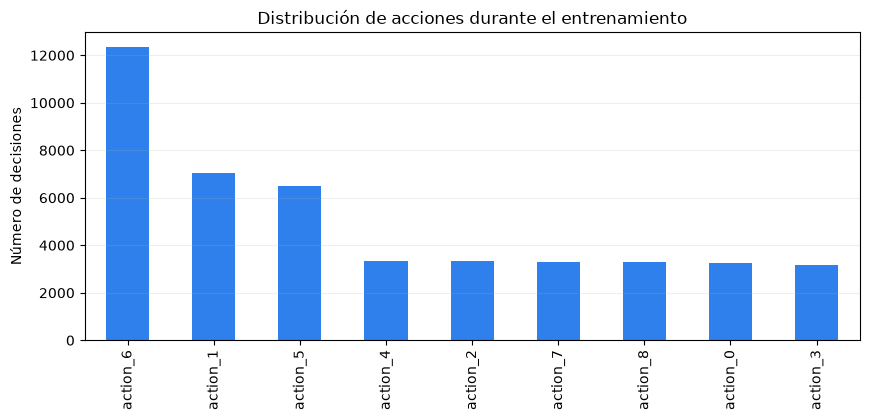

In [6]:
action_columns = [column for column in logs.columns if column.startswith('action_')]
usage = logs[action_columns].sum().sort_values(ascending=False)
usage.plot(kind='bar', figsize=(10,4), color='#2F80ED')
plt.ylabel('Número de decisiones')
plt.title('Distribución de acciones durante el entrenamiento')
plt.grid(axis='y', alpha=.2)
plt.show()


## Interpretación final

Responde con datos: ¿aumentó el éxito?, ¿disminuyeron las colisiones?, ¿la política depende demasiado de una acción?, ¿qué episodio marca un cambio sostenido?, ¿el modelo conserva su desempeño al evaluar sin exploración?